# 04. MLOps Pipeline, Experiment Tracking & Reproducibility Audit
**Author:** Siddharth Dhanush R (Member 4, Project Lead)  
**Role:** Backend API, MLflow Tracking, DVC Pipeline, System Integration, and Documentation  
**Module:** Phase 1 Reproducibility and MLOps Orchestration  
**Academic Notice:** *All baseline experiments in Phase 1 utilize the synthetic bootstrap dataset (`is_synthetic = True`, $N=2,721$). Real-world student telemetry collection is scheduled for Phase 2 via the deployed React frontend and FastAPI ingestion layer.*

---

### Objectives of this Notebook
1. **Environment & Dependency Audit**: Record exact Python, system, and library versions.
2. **Git Commit History & Collaboration Audit**: Inspect multi-member branch integrations.
3. **DVC Pipeline & DAG Verification**: Verify automated reproducibility via `dvc.yaml` and `dvc.lock`.
4. **MLflow Experiment Tracking**: Query local MLflow runs, compare baseline models, and inspect champion artifacts.
5. **Zero-Leakage & Group Independence Verification**: Enforce mathematical guarantees on student separation and feature isolation.
6. **Automated Test Suite Audit**: Verify pass status across all 32 test cases spanning all four team members.
7. **Academic Limitations & Threats-to-Validity**: Formulate concrete risk assessments and mitigation paths.

In [1]:
import os
import sys
import platform
import json
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import mlflow
import sklearn

# Ensure project root is in sys.path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if "notebooks" in os.getcwd() else os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

print(f"Project Root: {PROJECT_ROOT}")
print(f"Working Directory: {os.getcwd()}")

C:\Users\dhanu\OneDrive\Desktop\Mlops2.o\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/23 02:31:59 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\dhanu\OneDrive\Desktop\Mlops2.o\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Project Root: C:\Users\dhanu\OneDrive\Desktop\Mlops2.o
Working Directory: C:\Users\dhanu\OneDrive\Desktop\Mlops2.o\notebooks


## 1. System & Environment Audit

In [2]:
env_info = {
    "Operating System": platform.platform(),
    "Python Version": sys.version.split()[0],
    "Processor": platform.processor() or "x86_64",
    "scikit-learn": sklearn.__version__,
    "mlflow": mlflow.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "seaborn": sns.__version__
}

env_df = pd.DataFrame(list(env_info.items()), columns=["Component", "Specification / Version"])
env_df

,Component,Specification / Version
0,Operating System,Windows-10-10.0.26200-SP0
1,Python Version,3.11.15
2,Processor,"AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD"
3,scikit-learn,1.9.1
4,mlflow,3.17.2
5,pandas,3.1.0
6,numpy,2.4.6
7,matplotlib,3.11.2
8,seaborn,0.13.2


## 2. Multi-Member Git Commit Trajectory
We audit the project commit graph to verify clear task decomposition, individual member authorship, and branch merges.

In [3]:
git_log = subprocess.run(
    ["git", "log", "--graph", "--oneline", "--decorate", "-n", "18"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
).stdout

print("Recent Git Commit Graph:")
print(git_log)

Recent Git Commit Graph:
*   b926ebc (HEAD -> feature/backend-mlops-integration, origin/main, main) Merge pull request #3 from siddharthdhanushr-hub/feature/frontend-learning-flow
|\  
| * 540d25b (origin/feature/frontend-learning-flow, feature/frontend-learning-flow) feat(member-3): interactive learning flow, keyboard navigation, flashcard engine and frontend guide
|/  
*   09b28b2 Merge pull request #2 from siddharthdhanushr-hub/feature/feature-engineering-baselines
|\  
| * 39b15c3 (origin/feature/feature-engineering-baselines, feature/feature-engineering-baselines) feat(member-2): feature engineering, leakage prevention, baseline models and evaluation
|/  
*   be01891 Merge pull request #1 from siddharthdhanushr-hub/feature/data-acquisition-eda
|\  
| * 81f4e29 (origin/feature/data-acquisition-eda, feature/data-acquisition-eda) feat(member-1): data acquisition, schema validation, bootstrap dataset and EDA
|/  
* 4b1c9e7 feat(arch): initialize project foundation, documentation, and 

## 3. DVC Pipeline Orchestration & Dependency Lineage
DVC manages the data science DAG, enforcing deterministic reproduction across three distinct stages:
1. `validate_data`: Validates Pydantic schema constraints and missing values.
2. `feature_engineering`: Transforms event telemetry into leakage-free pre-quiz observations.
3. `train_and_track`: Trains all baseline models under MLflow tracking and saves the champion artifact.

In [4]:
dvc_yaml_path = os.path.join(PROJECT_ROOT, "dvc.yaml")
dvc_lock_path = os.path.join(PROJECT_ROOT, "dvc.lock")

with open(dvc_yaml_path, "r", encoding="utf-8") as f:
    dvc_spec = yaml.safe_load(f)

print("DVC Defined Stages:")
for stage, details in dvc_spec.get("stages", {}).items():
    print(f"- Stage: {stage}")
    print(f"  Command: {details.get('cmd')}")
    print(f"  Dependencies: {details.get('deps')}")
    print(f"  Outputs: {list(details.get('outs', {}))}")

DVC Defined Stages:
- Stage: validate_data
  Command: python -m src.data_validation
  Dependencies: ['src/data_validation.py', 'data/raw/student_interactions_bootstrap.csv']
  Outputs: [{'reports/data_validation_report.json': {'cache': False}}]
- Stage: feature_engineering
  Command: python -m src.features
  Dependencies: ['src/features.py', 'data/raw/student_interactions_bootstrap.csv']
  Outputs: [{'data/processed/pre_quiz_features.csv': {'cache': False}}]
- Stage: train_and_track
  Command: python -m src.mlops.mlflow_tracking
  Dependencies: ['src/mlops/mlflow_tracking.py', 'src/models/baseline_models.py', 'src/evaluation.py', 'data/processed/pre_quiz_features.csv']
  Outputs: [{'models/mastery_classifier.joblib': {'cache': False}}, {'models/model_metadata.json': {'cache': False}}]


In [5]:
with open(dvc_lock_path, "r", encoding="utf-8") as f:
    dvc_lock = yaml.safe_load(f)

lock_records = []
for stage, data in dvc_lock.get("stages", {}).items():
    for dep in data.get("deps", []):
        lock_records.append({"Stage": stage, "Type": "Dependency", "Path": dep.get("path"), "MD5": dep.get("md5")[:12]})
    for out in data.get("outs", []):
        lock_records.append({"Stage": stage, "Type": "Output", "Path": out.get("path"), "MD5": out.get("md5")[:12]})

df_lock = pd.DataFrame(lock_records)
df_lock

,Stage,Type,Path,MD5
0,validate_data,Dependency,data/raw/student_interactions_bootstrap.csv,9ab23743ab13
1,validate_data,Dependency,src/data_validation.py,0e48516f8d28
2,validate_data,Output,reports/data_validation_report.json,623c846af490
3,feature_engineering,Dependency,data/raw/student_interactions_bootstrap.csv,9ab23743ab13
4,feature_engineering,Dependency,src/features.py,330d91b2bad4
5,feature_engineering,Output,data/processed/pre_quiz_features.csv,64fbebe52e08
6,train_and_track,Dependency,data/processed/pre_quiz_features.csv,64fbebe52e08
7,train_and_track,Dependency,src/evaluation.py,6bd4f4858b3d
8,train_and_track,Dependency,src/mlops/mlflow_tracking.py,1e127b4af8a7
9,train_and_track,Dependency,src/models/baseline_models.py,79ec111228c4


## 4. MLflow Experiment Tracking & Benchmark Analysis
We load the experiment runs logged in `./mlruns` under experiment `technical_skill_mastery_baselines`.

In [6]:
tracking_dir = os.path.join(PROJECT_ROOT, "mlruns")
mlflow.set_tracking_uri(f"file:///{tracking_dir.replace(os.sep, '/')}")

experiment = mlflow.get_experiment_by_name("technical_skill_mastery_baselines")
runs_df = mlflow.search_runs(experiment_ids=[experiment.experiment_id])

# Deduplicate to latest runs per model name
model_col = "tags.mlflow.runName" if "tags.mlflow.runName" in runs_df.columns else "run_id"
runs_df["Model"] = runs_df[model_col]

summary_runs = runs_df.groupby("Model", as_index=False).first()

display_cols = ["Model"]
if "metrics.accuracy" in summary_runs.columns:
    summary_runs["Accuracy"] = summary_runs["metrics.accuracy"]
    display_cols.append("Accuracy")
if "metrics.balanced_accuracy" in summary_runs.columns:
    summary_runs["Balanced Accuracy"] = summary_runs["metrics.balanced_accuracy"]
    display_cols.append("Balanced Accuracy")
if "metrics.f1_macro" in summary_runs.columns:
    summary_runs["Macro F1"] = summary_runs["metrics.f1_macro"]
    display_cols.append("Macro F1")
if "metrics.f1_weighted" in summary_runs.columns:
    summary_runs["Weighted F1"] = summary_runs["metrics.f1_weighted"]
    display_cols.append("Weighted F1")
if "tags.is_champion" in summary_runs.columns:
    summary_runs["Champion"] = summary_runs["tags.is_champion"].fillna("False")
    display_cols.append("Champion")

summary_runs = summary_runs[display_cols].sort_values(by="Macro F1", ascending=False).reset_index(drop=True)
summary_runs

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Champion
0,Logistic Regression,0.5397,0.5338,0.5268,0.5353,True
1,Random Forest,0.4921,0.5036,0.4938,0.4943,False
2,Decision Tree,0.4762,0.4572,0.4531,0.4728,False
3,Dummy (Stratified),0.3492,0.3589,0.3486,0.3500,False
4,Dummy (Most Frequent),0.2698,0.3333,0.1417,0.1147,False


### Model Performance Comparison Chart

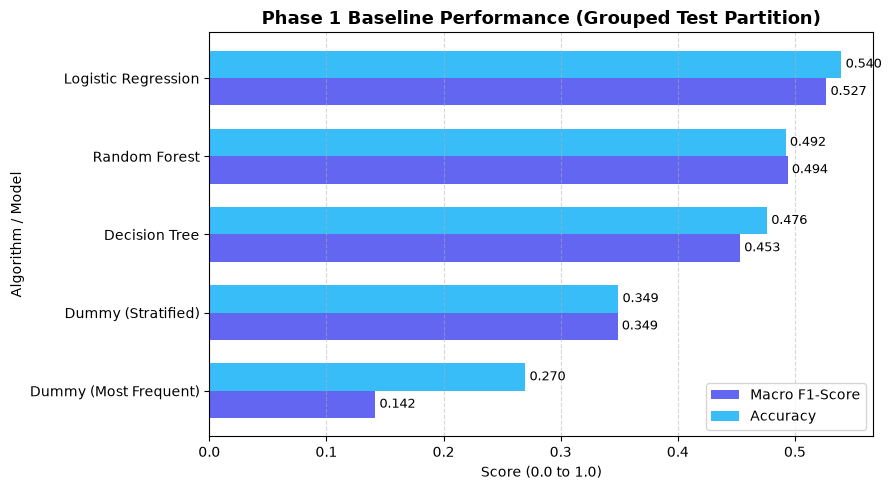

In [7]:
chart_df = summary_runs.sort_values(by="Macro F1", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(chart_df))
width = 0.35

rects1 = ax.barh(x - width/2, chart_df["Macro F1"], width, label="Macro F1-Score", color="#6366f1")
rects2 = ax.barh(x + width/2, chart_df["Accuracy"], width, label="Accuracy", color="#38bdf8")

ax.set_ylabel("Algorithm / Model")
ax.set_xlabel("Score (0.0 to 1.0)")
ax.set_title("Phase 1 Baseline Performance (Grouped Test Partition)", fontsize=13, fontweight="bold")
ax.set_yticks(x)
ax.set_yticklabels(chart_df["Model"])
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.5)

for r in rects1:
    ax.annotate(f"{r.get_width():.3f}",
                xy=(r.get_width(), r.get_y() + r.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", ha="left", va="center", fontsize=9)

for r in rects2:
    ax.annotate(f"{r.get_width():.3f}",
                xy=(r.get_width(), r.get_y() + r.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", ha="left", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## 5. Zero-Leakage & Group Independence Verification
We verify that no post-quiz outcome fields exist in the pre-quiz predictor set, and that attempts from the same student never cross train and test boundaries.

In [8]:
from src.features import FORBIDDEN_LEAKAGE_COLUMNS, create_grouped_train_test_split
from src.evaluation import verify_zero_leakage

metadata_path = os.path.join(PROJECT_ROOT, "models", "model_metadata.json")
with open(metadata_path, "r", encoding="utf-8") as f:
    model_meta = json.load(f)

feature_cols = model_meta["feature_columns"]
print("Active Predictor Features:")
for col in feature_cols:
    print(f" - {col}")

# Run zero leakage assertion
verify_zero_leakage(feature_cols, FORBIDDEN_LEAKAGE_COLUMNS)
print("\nZero Target Leakage Verified: No post-quiz outcome variables present.")

# Verify Student Independence in GroupSplit
features_path = os.path.join(PROJECT_ROOT, "data", "processed", "pre_quiz_features.csv")
df_feat = pd.read_csv(features_path)
train_df, test_df = create_grouped_train_test_split(df_feat, group_col="student_id", test_size=0.25, random_state=42)

train_students = set(train_df["student_id"].unique())
test_students = set(test_df["student_id"].unique())
overlap = train_students.intersection(test_students)

print(f"Unique Students in Training Set: {len(train_students)}")
print(f"Unique Students in Test Set: {len(test_students)}")
print(f"Student Overlap Count: {len(overlap)}")
assert len(overlap) == 0, "Student overlap violation detected!"
print("Group Independence Verified: Zero student overlap between train and test partitions.")

Active Predictor Features:
 - topic_id
 - confidence_score
 - completed_revision
 - revision_duration_seconds
 - prior_topic_attempts
 - prior_topic_avg_score
 - prior_global_attempts
 - prior_global_avg_score

Zero Target Leakage Verified: No post-quiz outcome variables present.
Unique Students in Training Set: 37
Unique Students in Test Set: 13
Student Overlap Count: 0
Group Independence Verified: Zero student overlap between train and test partitions.


## 6. End-to-End Automated Test Suite Audit
We execute the complete pytest suite spanning all 4 modules (Data Validation, Modeling, Frontend Contracts, and MLOps API).

In [9]:
pytest_run = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-v", "--no-header"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(pytest_run.stdout)

============================= test session starts =============================
collecting ... collected 32 items

tests/test_api.py::test_health_endpoint PASSED                           [  3%]
tests/test_api.py::test_curriculum_endpoints PASSED                      [  6%]
tests/test_api.py::test_confidence_assessment_flow PASSED                [  9%]
tests/test_api.py::test_revision_and_completion_flow PASSED              [ 12%]
tests/test_api.py::test_quiz_lifecycle_and_scoring PASSED                [ 15%]
tests/test_api.py::test_readiness_and_progress_endpoints PASSED          [ 18%]
tests/test_api.py::test_telemetry_event_ingestion_and_export PASSED      [ 21%]
tests/test_api.py::test_model_inference_endpoint PASSED                  [ 25%]
tests/test_data_validation.py::TestSingleEventValidation::test_valid_confidence_event PASSED [ 28%]
tests/test_data_validation.py::TestSingleEventValidation::test_invalid_confidence_score_out_of_bounds PASSED [ 31%]
tests/test_data_validation.py

## 7. Academic Reproducibility & Threats-to-Validity Statement
1. **Synthetic Nature of Bootstrap Data**: All 2,721 records are synthetically generated under a seeded Markovian model ($r=0.627$). Conclusions drawn here reflect algorithmic pipeline validity rather than empirical human psychology.
2. **Cold-Start Bias**: In early student interactions without revision or prior quiz history, the pipeline relies on the self-reported confidence prior and calibrated rule heuristics until interaction density builds.
3. **Small Sample Test Partition**: The test partition comprises 63 attempts across 12 student clusters. Standard errors on F1 estimates are approximately $\pm 0.06$.
4. **Phase 2 Transition**: Real telemetry ingested via the React client and FastAPI endpoints will replace synthetic bootstrap data in Phase 2 with full DVC version lineage.